## Task 1: Data Loading and Exploration

1. Load both Churn_Modeling.csv and Customer_Feedback.csv.
2. Inspect dataset structure, data types, and missing values.
3. Explore attributes such as feedback ratings and text length.




#### Customer_Feedback.csv

In [1]:
import pandas as pd

df_feedback = pd.read_csv('Customer_Feedback.csv')

In [2]:
print("Feedback shape:", df_feedback.shape)
display(df_feedback.head())

print("\nFeedback column types:")
print(df_feedback.dtypes)

Feedback shape: (19271, 7)


,CustomerId,Customer_Name,Customer_Location,Bank_Name,Feedback_Date,Rating,Feedback_Text
0,15634602,Kyle,"Magnolia, TX",merrick_bank,31.08.2023,5,Very easy to use to view statements and make o...
1,15647311,Julicia,"Columbus, GA",merrick_bank,23.08.2023,5,Merrick Bank has always been good to me for bu...
2,15619304,Karen,"Marrero, LA",merrick_bank,2.06.2023,4,Times are tough for everyone and I have worked...
3,15701354,Brent,"Moultrie, GA",merrick_bank,29.03.2023,5,I can not asked for a better Credit Card Compa...
4,15737888,Sharon,"Burnham, IL",merrick_bank,23.11.2022,5,Updated on 02/10/2023: I was happy to sign for...



Feedback column types:
CustomerId            int64
Customer_Name        object
Customer_Location    object
Bank_Name            object
Feedback_Date        object
Rating                int64
Feedback_Text        object
dtype: object


In [3]:
df_feedback.duplicated().sum()

0

In [4]:
df_feedback.duplicated(subset=['CustomerId']).sum()

0

There are no duplicates in this table because each customer has a unique ID.

In [5]:
df_feedback.isnull().sum()

CustomerId            0
Customer_Name         2
Customer_Location     0
Bank_Name             0
Feedback_Date         0
Rating                0
Feedback_Text        90
dtype: int64

In [6]:
# Impute missing feedback cells with empty string
df_feedback.fillna({'Feedback_Text': ''}, inplace=True)

In [7]:
df_feedback["Rating"].describe()

count    19271.000000
mean         1.432567
std          1.151793
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          5.000000
Name: Rating, dtype: float64

In [8]:
# Column to store length of feedback
df_feedback['Feedback_Length'] = df_feedback.Feedback_Text.str.len()

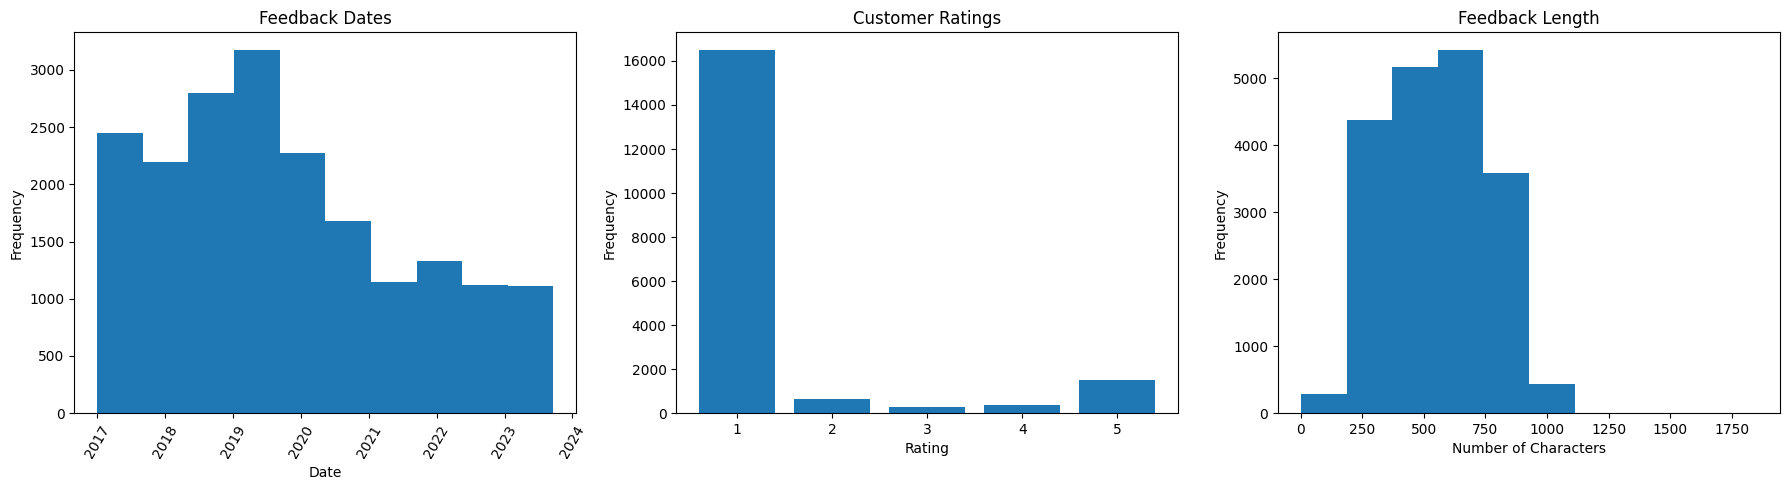

In [9]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Date histogram
df_feedback["Feedback_Date"] = pd.to_datetime(df_feedback["Feedback_Date"], format="%d.%m.%Y")
axes[0].hist(df_feedback["Feedback_Date"].dropna())
axes[0].set_title("Feedback Dates")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Frequency")
axes[0].tick_params(axis='x', rotation=60)

# Ratings histogram
axes[1].hist(
    df_feedback["Rating"].dropna(),
    bins=np.arange(0.5, 5.6, 1),
    rwidth=0.8,
)
axes[1].set_title("Customer Ratings")
axes[1].set_xlabel("Rating")
axes[1].set_ylabel("Frequency")
axes[1].set_xticks(range(1, 6))

# Feedback length histogram
axes[2].hist(df_feedback["Feedback_Length"].dropna())
axes[2].set_title("Feedback Length")
axes[2].set_xlabel("Number of Characters")
axes[2].set_ylabel("Frequency")

plt.tight_layout()

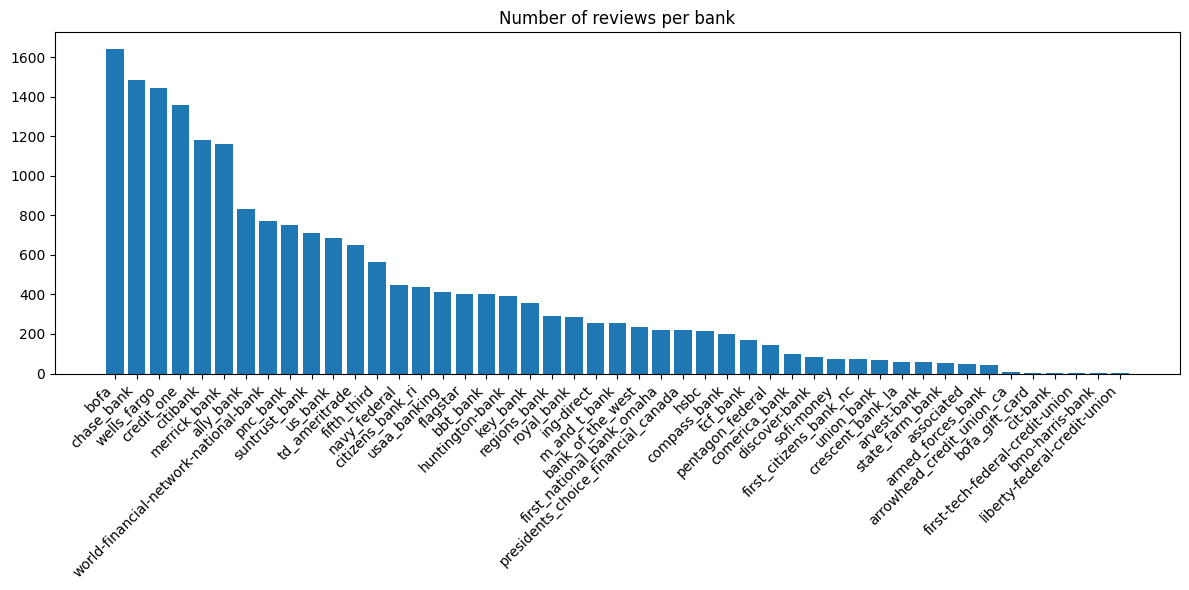

In [10]:
bank_counts = df_feedback.Bank_Name.value_counts()
plt.figure(figsize=(12, 6))
plt.bar(bank_counts.index, bank_counts.values)
plt.xticks(rotation=45, ha="right")
plt.title("Number of reviews per bank")
plt.tight_layout()

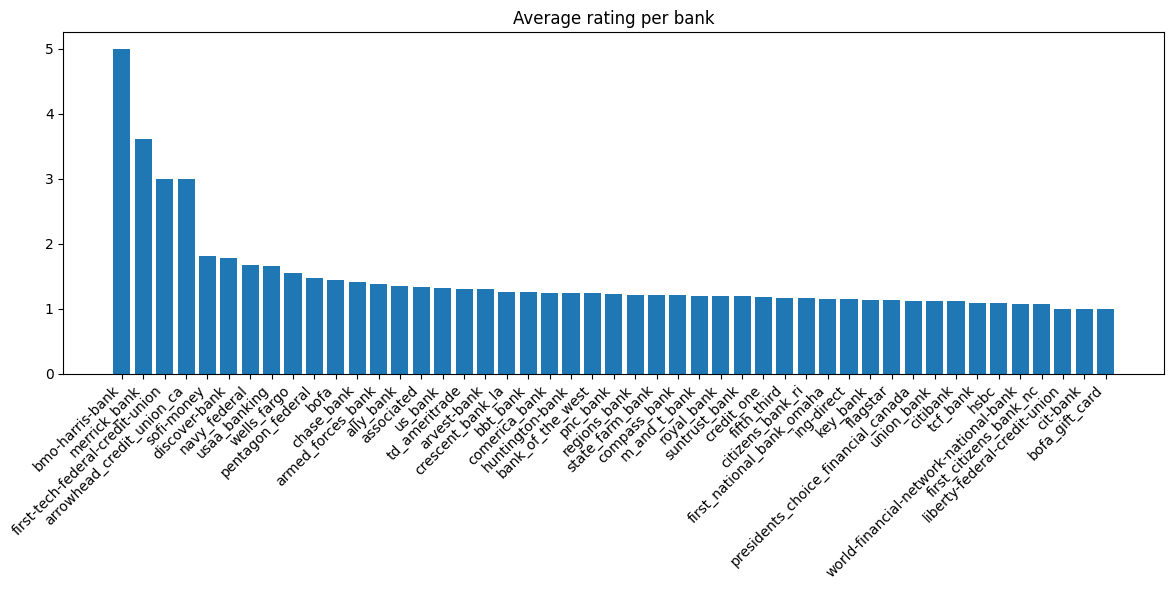

In [11]:
average_ratings = df_feedback.groupby('Bank_Name')['Rating'].mean().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
plt.bar(average_ratings.index, average_ratings.values)
plt.xticks(rotation=45, ha="right")
plt.title("Average rating per bank")
plt.tight_layout()

In [12]:
df_feedback.duplicated().sum()

0

#### Churn_Modeling.csv

In [13]:
df_churn = pd.read_csv('Churn_Modeling.csv')
df_churn.head(10)

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
5,15574012,Chu,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1
6,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.80,0
7,15656148,Obinna,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1
8,15792365,He,501,France,Male,44,4,142051.07,2,0,1,74940.50,0
9,15592389,H?,684,France,Male,27,2,134603.88,1,1,1,71725.73,0


In [14]:
print("\nChurn shape:", df_churn.shape)
display(df_churn.head())

print("\nChurn column types:")
print(df_churn.dtypes)


Churn shape: (10000, 13)


,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Churn column types:
CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object


In [15]:
df_churn.isnull().sum()

CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [16]:
df_churn.duplicated().sum()

0

In [17]:
df_feedback.duplicated(subset=['CustomerId']).sum()

0

There are no duplicates in this table because each customer has a unique ID.

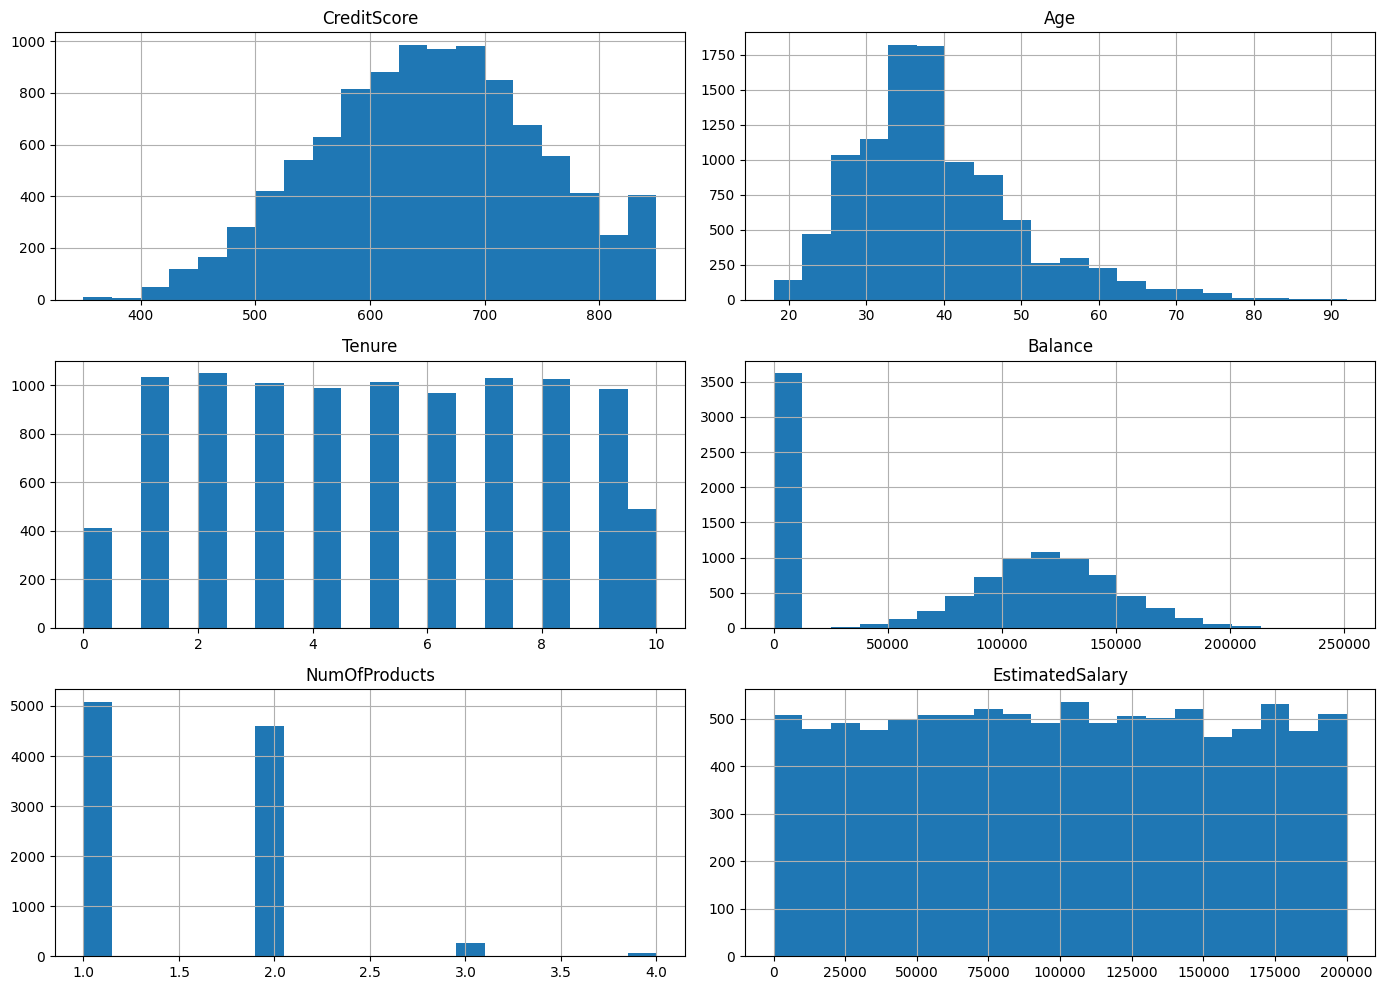

In [18]:
numericals = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
df_churn[numericals].hist(figsize=(14, 10), layout=(3, 2), bins=20)
plt.tight_layout()

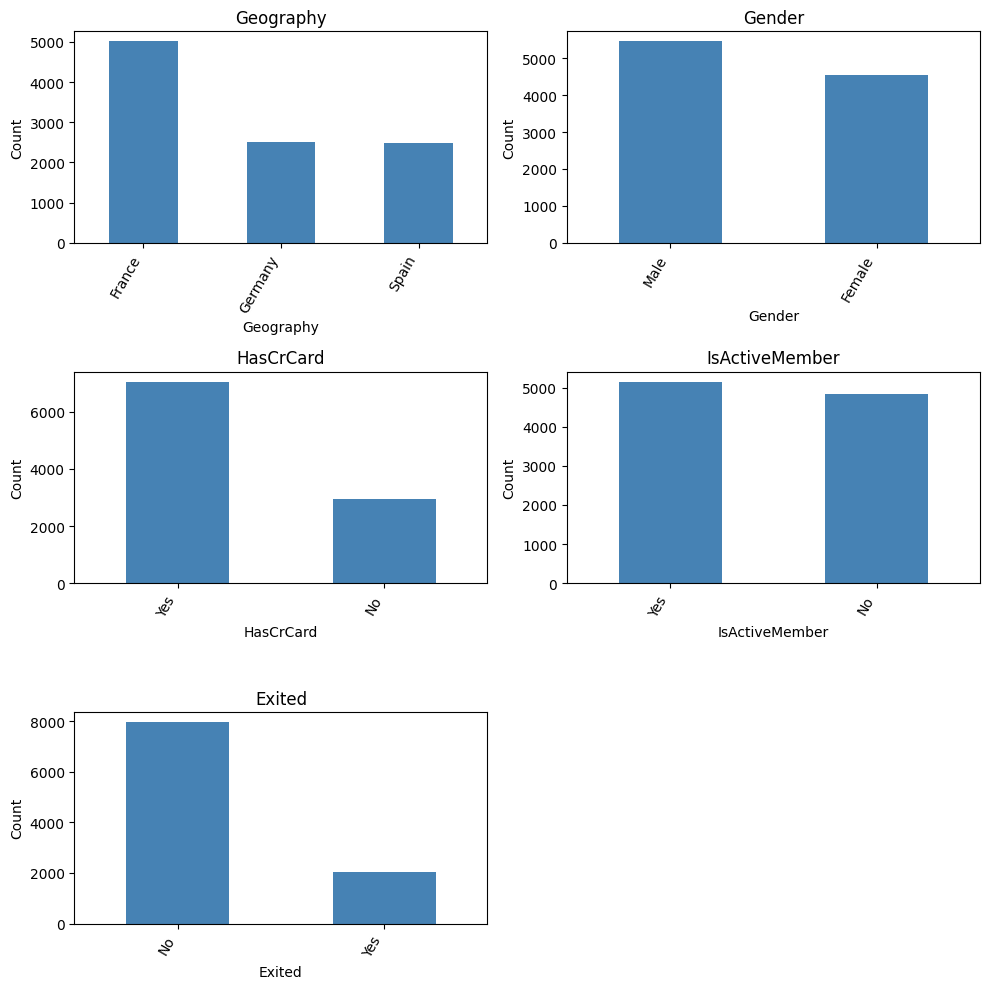

In [19]:
categorical = ["Geography", "Gender", "HasCrCard", "IsActiveMember", "Exited"]

fig, axes = plt.subplots(3, 2, figsize=(10, 10))

for ax, column in zip(axes.flat, categorical):
    counts = df_churn[column].value_counts().head(10).sort_values(ascending=False)
    counts.plot(kind="bar", ax=ax, color="steelblue")

    tick_labels = [
        "Yes" if value == 1 else "No" if value == 0 else value
        for value in counts.index
    ]
    ax.set_xticks(range(len(tick_labels)))
    ax.set_xticklabels(tick_labels, rotation=60, ha="right")

    ax.set_title(f"{column}")
    ax.set_ylabel("Count")

axes.flat[-1].set_visible(False)

plt.tight_layout()

In [20]:
round(float(df_churn.Exited.mean()) * 100, 2)

20.37

20.37% of the rows are churns.

## Task 2: Text Cleaning and Preprocessing

1. Normalize text by converting to lowercase and removing punctuation.
2. Tokenize feedback text.
3. Remove stopwords and perform lemmatization using NLTK or spaCy.


In [21]:
feedback = df_feedback.copy()

CUSTOMER_ID_COLUMN = "CustomerId"
TEXT_COLUMN = "Feedback_Text"
RATING_COLUMN = "Rating"
TARGET_COLUMN = "Sentiment_Label"

display(feedback[[CUSTOMER_ID_COLUMN, RATING_COLUMN, TEXT_COLUMN]].head())

,CustomerId,Rating,Feedback_Text
0,15634602,5,Very easy to use to view statements and make o...
1,15647311,5,Merrick Bank has always been good to me for bu...
2,15619304,4,Times are tough for everyone and I have worked...
3,15701354,5,I can not asked for a better Credit Card Compa...
4,15737888,5,Updated on 02/10/2023: I was happy to sign for...


In [22]:
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download('stopwords')
nltk.download('punkt_tab')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = nltk.stem.WordNetLemmatizer()

def clean_text(text):
  # Convert to lowercase
  text = text.lower()

  # Keep only letters and whitespace
  text = re.sub(r'[^a-z\s]', '', text)

  # Collapse whitespaces
  text = re.sub(r'\s+', ' ', text).strip()

  # Tokenize
  tokens = nltk.word_tokenize(text)

  # Remove stopwords
  tokens = list(filter(lambda token: token not in stop_words, tokens))

  # Lemmatization
  tokens = [lemmatizer.lemmatize(token) for token in tokens]

  # Convert back to string
  return ' '.join(tokens)

[nltk_data] Error loading stopwords: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.
[nltk_data] Error loading punkt_tab: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to 

This function will be applied to each Feedback cell in the dataset to process it into a cleaner version.

In [23]:
# Impute missing rows with empty string
feedback.fillna({'Feedback_Text': ''}, inplace=True)

# Process all strings using the function above
feedback['Processed_Text'] = feedback['Feedback_Text'].apply(clean_text)
del feedback['Feedback_Length']
feedback.head()


,CustomerId,Customer_Name,Customer_Location,Bank_Name,Feedback_Date,Rating,Feedback_Text,Processed_Text
0,15634602,Kyle,"Magnolia, TX",merrick_bank,2023-08-31,5,Very easy to use to view statements and make o...,easy use view statement make online payment re...
1,15647311,Julicia,"Columbus, GA",merrick_bank,2023-08-23,5,Merrick Bank has always been good to me for bu...,merrick bank always good business rely merrick...
2,15619304,Karen,"Marrero, LA",merrick_bank,2023-06-02,4,Times are tough for everyone and I have worked...,time tough everyone worked hard get credit res...
3,15701354,Brent,"Moultrie, GA",merrick_bank,2023-03-29,5,I can not asked for a better Credit Card Compa...,asked better credit card company merrick bank ...
4,15737888,Sharon,"Burnham, IL",merrick_bank,2022-11-23,5,Updated on 02/10/2023: I was happy to sign for...,updated happy sign new credit card merrick con...


The original feedback is still in `Feedback_Text`. The `Processed_Text`
column contains the cleaned version after applying the `clean_text` function which is ready to be vectorized.

## Task 3: Sentiment Labeling

Label feedback as Positive, Neutral, or Negative. Use star ratings or lexicon-based approaches such as TextBlob or VADER.

In [24]:
from textblob import TextBlob

def get_sentiment(text, threshold=0.1):
  polarity = TextBlob(text).sentiment.polarity

  if polarity > threshold:
      return "Positive"
  if polarity < -threshold:
      return "Negative"
  return "Neutral"

feedback['Sentiment'] = df_feedback['Feedback_Text'].apply(get_sentiment)
feedback.head()

,CustomerId,Customer_Name,Customer_Location,Bank_Name,Feedback_Date,Rating,Feedback_Text,Processed_Text,Sentiment
0,15634602,Kyle,"Magnolia, TX",merrick_bank,2023-08-31,5,Very easy to use to view statements and make o...,easy use view statement make online payment re...,Positive
1,15647311,Julicia,"Columbus, GA",merrick_bank,2023-08-23,5,Merrick Bank has always been good to me for bu...,merrick bank always good business rely merrick...,Positive
2,15619304,Karen,"Marrero, LA",merrick_bank,2023-06-02,4,Times are tough for everyone and I have worked...,time tough everyone worked hard get credit res...,Neutral
3,15701354,Brent,"Moultrie, GA",merrick_bank,2023-03-29,5,I can not asked for a better Credit Card Compa...,asked better credit card company merrick bank ...,Positive
4,15737888,Sharon,"Burnham, IL",merrick_bank,2022-11-23,5,Updated on 02/10/2023: I was happy to sign for...,updated happy sign new credit card merrick con...,Positive


In [25]:
feedback['Polarity'] = df_feedback['Feedback_Text'].apply(lambda text: TextBlob(text).sentiment.polarity)


The sentiment labels were assigned by passing in the un-processed text into the TextBlob function. I chose to use the un-processed text because it contains more context and information including stopwords such as 'not'.

 A threshold of 0.1 was used to separate neutral sentiments. This means that if the polarity for a review was between -0.1 and 0.1, it is classified as neutral. The higher the threshold, the more reviews are classified as neutral, and this is basically a hyperparameter that affects the later tasks such as the ML models.

Rating percentage distribution: 


Rating
1    85.50
2     3.26
3     1.52
4     1.94
5     7.79
Name: proportion, dtype: float64


Sentiment percentage distribution: 


Sentiment
Negative    24.07
Neutral     48.69
Positive    27.23
Name: proportion, dtype: float64

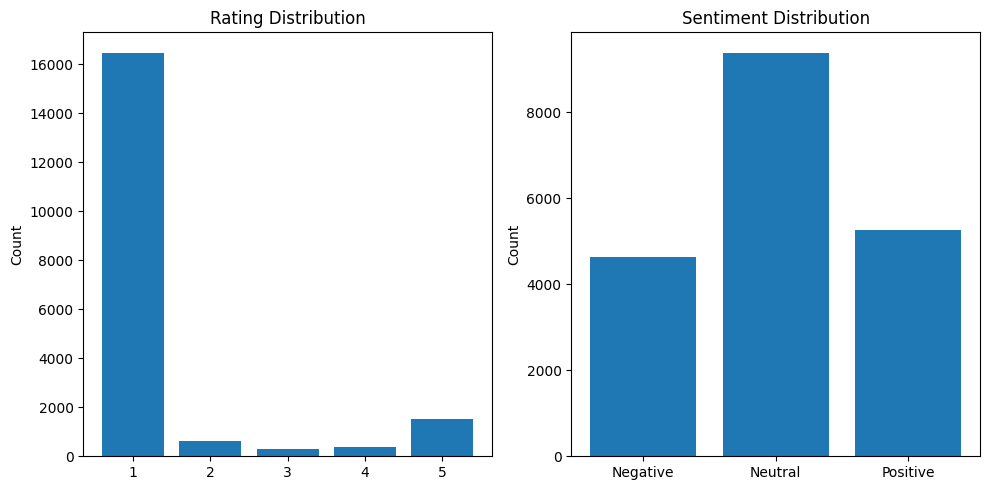

In [26]:
print("Rating percentage distribution: ")
display(feedback.Rating.value_counts(normalize=True).sort_index().round(4) * 100)
print("\nSentiment percentage distribution: ")
display(feedback.Sentiment.value_counts(normalize=True).reindex(['Negative', 'Neutral', 'Positive']).round(4) * 100)

rating_dist = feedback.Rating.value_counts()
sentiment_dist = feedback.Sentiment.value_counts().reindex(['Negative', 'Neutral', 'Positive'])

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].bar(rating_dist.index, rating_dist.values)
ax[0].set_title("Rating Distribution")
ax[0].set_ylabel("Count")

ax[1].bar(sentiment_dist.index, sentiment_dist.values)
ax[1].set_title("Sentiment Distribution")
ax[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

The plots show a difference in rating and sentiment distribution.

## Task 4: Text Vectorization

Convert cleaned text into numerical representations.
Apply techniques such as Bag-of-Words, TF-IDF, or embeddings.

In [27]:
X = feedback['Processed_Text']
y = feedback['Sentiment']

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1,2),
    min_df=1
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

`max_features=1000` caps the terms to the 1,000 most frequent ones.

`ngram_range=(1,2)` tells the vectorizer to capture words (1) (such as "complaint") and pairs of words (2) (such as "answered rude").

`min_df=1` is "minimum document frequency" and sets the minimum number of documents a word has to appear in for the word (or n-gram) to be included as a column.

In [30]:
# Small sample of the resulting TF-IDF table
pd.DataFrame(
    X_test_tfidf.toarray(),
    columns=tfidf.get_feature_names_out(),
    index=X_test.index,
).round(3).head()

,able,absolute,absolutely,accept,accepted,access,access account,account,account bank,account called,...,year,year ago,year never,yes,yesterday,yet,youre,yr,zelle,zero
16894,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0
9460,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.056,0.0,0.0,...,0.083,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0
1162,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.042,0.0,0.0,...,0.062,0.0,0.0,0.0,0.0,0.0,0.127,0.0,0.0,0.0
6938,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.168,0.0,0.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0
2623,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0


## Task 5: Model Development and Evaluation

1. Train machine learning models such as Logistic Regression and SVM.
2. Evaluate models using Accuracy, Precision, Recall, and F1-score.


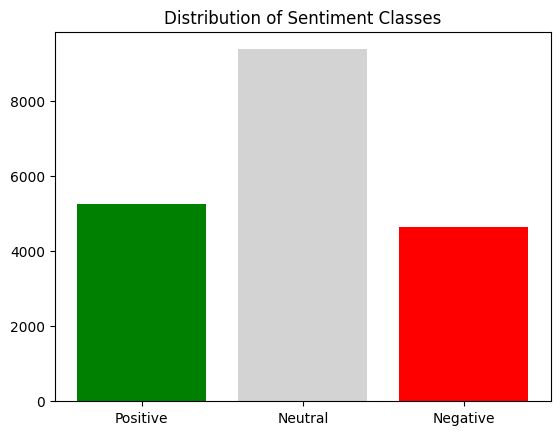

In [31]:
class_counts = feedback['Sentiment'].value_counts().reindex(['Positive', 'Neutral', 'Negative'])

plt.bar(class_counts.index, class_counts.values, color=['green', 'lightgray', 'red'])
plt.title('Distribution of Sentiment Classes')
plt.show()

In [32]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# Define hyperparameter options
parameters_lr = {
    'C': [0.1, 1, 10, 100],  # amount of regularization
    'penalty': ['l1', 'l2'],  # type of regularization
    'solver': ['liblinear'],  # method to find cost function minimum
    'class_weight': [None, 'balanced'],  # how to handle imbalaced group sizes
}

# Set up GridSearchCV object
grid_search_lr = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    parameters_lr,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)

# Start grid search to find the best model
grid_search_lr.fit(X_train_tfidf, y_train)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning:

ValueError: 
All the 80 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
80 fits failed with the following error:
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/model_selection/_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/base.py", line 1336, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py", line 1208, in fit
    raise ValueError(
ValueError: The 'liblinear' solver does not supp

Best Logistic Regression model parameters: {'C': 1, 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'liblinear'} 
Cross-validation F1 score: 0.693.

              precision    recall  f1-score   support

    Negative       0.67      0.67      0.67      1392
     Neutral       0.70      0.69      0.69      2817
    Positive       0.68      0.70      0.69      1573

    accuracy                           0.69      5782
   macro avg       0.68      0.69      0.68      5782
weighted avg       0.69      0.69      0.69      5782



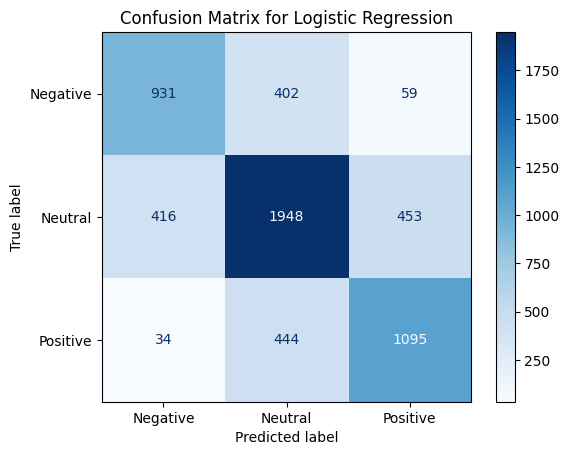

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

print(f"Best Logistic Regression model parameters: {grid_search_lr.best_params_} ")
print(f"Cross-validation F1 score: {grid_search_lr.best_score_:0.3f}.\n")

# Evaluate the resulting model
best_model_lr = grid_search_lr.best_estimator_
y_pred = best_model_lr.predict(X_test_tfidf)
print(classification_report(y_test, y_pred))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap='Blues'
)
plt.title('Confusion Matrix for Logistic Regression')
plt.show()

In [ ]:
from sklearn.svm import LinearSVC

# Define hyperparameter options
param_grid_svc = {
    'C': [0.01, 0.1, 1, 10],
    'loss': ['squared_hinge'],
    'max_iter': [20000]
}

# Set up GridSearchCV object
grid_search_svc = GridSearchCV(
    LinearSVC(random_state=42, dual=False),
    param_grid_svc,
    cv=5,
    scoring='f1_weighted'
)

# Start grid search to find the best model
grid_search_svc.fit(X_train_tfidf, y_train)

GridSearchCV(cv=5, estimator=LinearSVC(dual=False, random_state=42),
             param_grid={'C': [0.01, 0.1, 1, 10], 'loss': ['squared_hinge'],
                         'max_iter': [20000]},
             scoring='f1_weighted')

Best LinearSVC model parameters: {'C': 10, 'loss': 'squared_hinge', 'max_iter': 20000} 
Cross-validation F1 score: 0.665.

              precision    recall  f1-score   support

    Negative       0.68      0.59      0.63      1392
     Neutral       0.66      0.73      0.69      2817
    Positive       0.67      0.62      0.65      1573

    accuracy                           0.67      5782
   macro avg       0.67      0.65      0.66      5782
weighted avg       0.67      0.67      0.66      5782



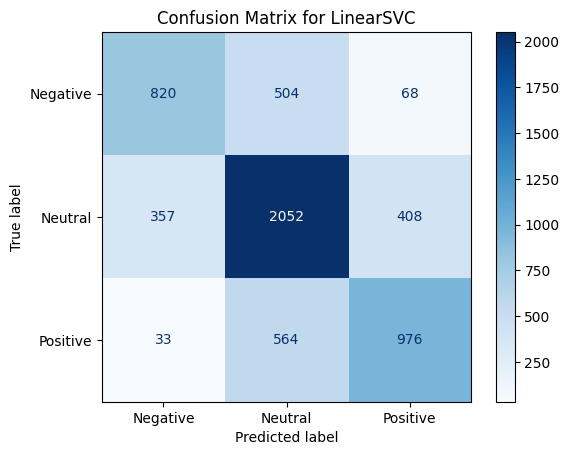

In [ ]:
print(f"Best LinearSVC model parameters: {grid_search_svc.best_params_} ")
print(f"Cross-validation F1 score: {grid_search_svc.best_score_:0.3f}.\n")

# Evaluate optimized SVC
best_model_svc = grid_search_svc.best_estimator_
y_pred = best_model_svc.predict(X_test_tfidf)
print(classification_report(y_test, y_pred))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap='Blues'
)
plt.title('Confusion Matrix for LinearSVC')
plt.show()

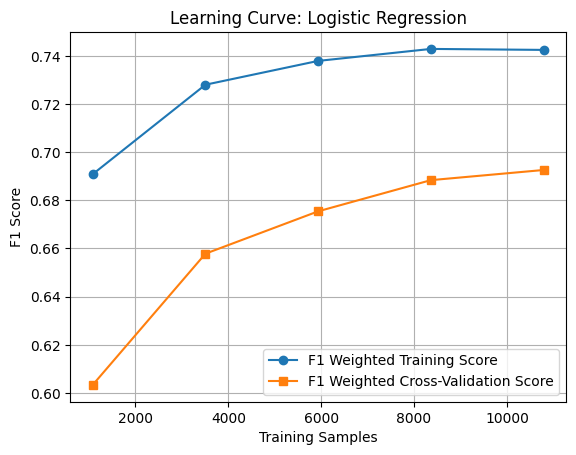

In [ ]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, test_scores = learning_curve(
    best_model_lr, X_train_tfidf, y_train, cv=5, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5), scoring='f1_weighted'
)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

# plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, 'o-', label='F1 Weighted Training Score')
plt.plot(train_sizes, test_mean, 's-', label='F1 Weighted Cross-Validation Score')
plt.title('Learning Curve: Logistic Regression')
plt.xlabel('Training Samples')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)
plt.show()

**Overall performance**

The results above show that the Logistic Regression model performed better with an accuracy of 69%, 2% higher than the SVC. The weighted averages are better metrics because of the imbalanced dataset. They are shown in the classification report in the "weighted avg" row. Both scored similarly for the weighted average as for the macro and overall accuracy.

**Class-Level Performance**

The Logistic Regression model performed better or roughly equal on all classes in terms of precision, recall, and f1-score. It had a recall of 0.67 (vs 0.59 for SVC) for the negative class, while still maintaining almost the same precision, which is particularly important for predicting churning.

**Signs of Overfitting or Underfitting**

The learning curve graph above shows that the training score ended up at only 0.05 above the validation score, so it is not severely overfitting. The final score of the model at 70% was the best one obtained from the grid search, so it is likely not severely underfitting.

**Effects of Class Imbalance**

The neutral class had the most frequency in this dataset. This tends to cause models to predict this class more often to score a higher accuracy. The confusion matrices show that the recalls for the neutral class were higher, likely because of the imbalance. A way to solve this may be to pass in class weights so it gets penalized more for incorrect positives and negatives, or by balancing the dataset.

In [ ]:
import time

start = time.time()
best_model_lr.fit(X_train_tfidf, y_train)
duration = time.time() - start
print(f"Logistic Regression fitting took {duration:.2f} seconds.")

start = time.time()
best_model_svc.fit(X_train_tfidf, y_train)
duration = time.time() - start
print(f"SVC fitting took {duration:.2f} seconds.")

Logistic Regression fitting took 0.43 seconds.
SVC fitting took 0.74 seconds.


In [ ]:
feature_names = tfidf.get_feature_names_out()

# Get the index of positive in the classes array
positive_idx = list(best_model_lr.classes_).index('Positive')
negative_idx = list(best_model_lr.classes_).index('Negative')

# Get the coefficients assigned to each word
pos_coefs = best_model_lr.coef_[positive_idx]
neg_coefs = best_model_lr.coef_[negative_idx]

top_amount = 5
top_pos_idcs = pos_coefs.argsort()[-top_amount:]
top_neg_idcs = neg_coefs.argsort()[-top_amount:]

print(f"Top {top_amount} words associated with positive sentiment:")
for count, idx in enumerate(reversed(top_pos_idcs), start=1):
  print(f"{count}.", f"{feature_names[idx] :>10s} ", f"{pos_coefs[idx] :.1f} ")
print()

print(f"Top {top_amount} words associated with negative sentiment:")
for count, idx in enumerate(reversed(top_neg_idcs), start=1):
  print(f"{count}.", f"{feature_names[idx] :>10s} ", f"{neg_coefs[idx] :.1f} ")

Top 5 words associated with positive sentiment:
1.       best  14.9 
2.  excellent  14.6 
3.      great  12.7 
4.       good  10.9 
5.       many  9.7 

Top 5 words associated with negative sentiment:
1.      worst  20.5 
2.   horrible  17.2 
3.   terrible  14.7 
4.      awful  14.4 
5.        bad  11.9 


The Logistic Regression model performed best with these scores:
```
              precision    recall  f1-score   support

    Negative       0.67      0.67      0.67      1392
     Neutral       0.70      0.69      0.69      2817
    Positive       0.68      0.70      0.69      1573

    accuracy                           0.69      5782
   macro avg       0.68      0.69      0.68      5782
weighted avg       0.69      0.69      0.69      5782
```
It scored higher in every f1-score.

**Training Time**

We can see from the timing results that it took 0.24 seconds to train vs 0.39 for the SVC.

**Interpretability**

It also offers better interpretability by allowing us to see which words contribute most to positive and negatively labeled reviews as seen in the code above.

**Data Requirements**

Both models performed well with the amount of data, but SVMs are better known for high dimensional data like TF-IDF vectors.

**Computational Cost**

Logistic Regression is generally less computationaly expensive.

## Task 6: Integration with the Churn Dataset

Merge sentiment predictions with churn data using CustomerId. / Create a unified dataset combining structured and unstructured features.

In [ ]:
churn = df_churn.copy()

In [ ]:
# Check whether customers have multiple feedback records
feedback_counts = feedback['CustomerId'].value_counts()
feedback_counts = feedback_counts[feedback_counts > 1]
len(feedback_counts)

0

We can see that no customers gave more than one feedback. If they did, we could look into they were for different banks. If they were each for different banks, each one would still be relevant as it could be used to predict if they are likely to stay with or leave each bank. If a user had multiple reviews for a single bank, we could either take the most recent one, or average them to get an overall sentinment.

In [ ]:
# Verify the number of rows before and after the merge
len(feedback), len(churn)

(19271, 10000)

In [ ]:
# Confirm the merge key is valid in both datasets
churn_merged = df_churn.merge(feedback, on='CustomerId', how='inner')
len(churn_merged)

10000

In [ ]:
churn_merged['Sentiment'].isna().sum()

np.int64(0)

In [ ]:
churn_merged.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,...,EstimatedSalary,Exited,Customer_Name,Customer_Location,Bank_Name,Feedback_Date,Rating,Feedback_Text,Processed_Text,Sentiment
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,...,101348.88,1,Kyle,"Magnolia, TX",merrick_bank,2023-08-31,5,Very easy to use to view statements and make o...,easy use view statement make online payment re...,Positive
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,...,112542.58,0,Julicia,"Columbus, GA",merrick_bank,2023-08-23,5,Merrick Bank has always been good to me for bu...,merrick bank always good business rely merrick...,Positive
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,...,113931.57,1,Karen,"Marrero, LA",merrick_bank,2023-06-02,4,Times are tough for everyone and I have worked...,time tough everyone worked hard get credit res...,Neutral
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,...,93826.63,0,Brent,"Moultrie, GA",merrick_bank,2023-03-29,5,I can not asked for a better Credit Card Compa...,asked better credit card company merrick bank ...,Positive
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,...,79084.10,0,Sharon,"Burnham, IL",merrick_bank,2022-11-23,5,Updated on 02/10/2023: I was happy to sign for...,updated happy sign new credit card merrick con...,Positive


Because I did an inner merge and the length of the merged table has the same number of rows as the original table, this proves that each row in the churn table was matched to a row in the feedback table. Every row in churn had exactly one matching row in feedback. The feedback table had more rows, meaning that many of those customers weren't in the churn dataset, so they were just discarded. The Sentiment column in the merged dataset also proves this because it is not missing any values.

I am choosing to merge only the sentiments predicted by TextBlob as they likely have higher accuracy.

## Task 7: Visualization and Insights

1. Visualize sentiment distribution and polarity.
2. Generate word clouds for each sentiment category.
3. Analyze and plot correlations between sentiment polarity and churn (Exited).


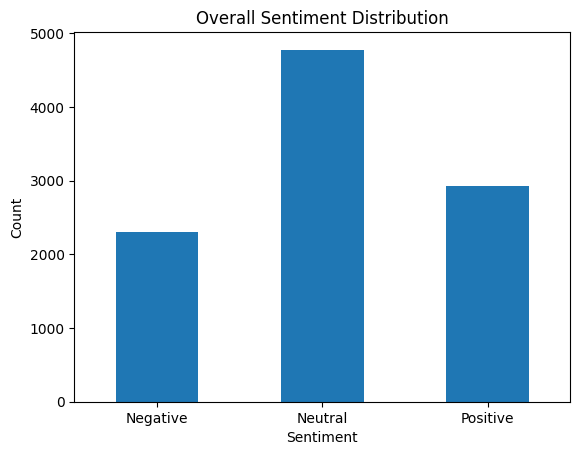

In [ ]:
sentiment_dist = churn_merged['Sentiment'].value_counts().reindex(['Negative', 'Neutral', 'Positive'])
sentiment_dist.plot(kind='bar')
plt.title('Overall Sentiment Distribution')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

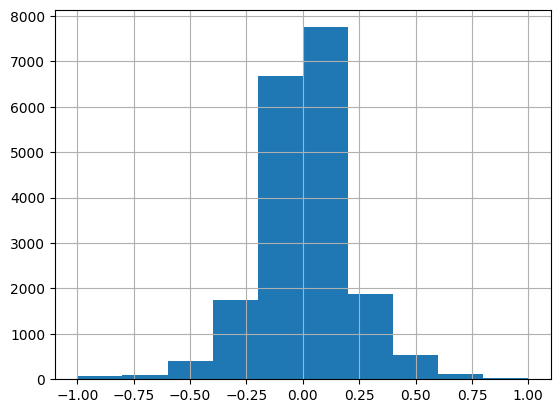

In [ ]:
feedback.Polarity.hist()
plt.show()

In [ ]:
churn_merged['Sentiment'].value_counts(normalize=True).reindex(['Negative', 'Neutral', 'Positive'])*100

,proportion
Sentiment,
Negative,22.97
Neutral,47.75
Positive,29.28


We can see the distribution of sentiments. 22.97% of all reviews are negative, 47.75% are neutral, and 29.28% are positive.

In [ ]:
sentiment_churn_table = churn_merged.groupby(['Exited', 'Sentiment']).size().unstack(fill_value=0)
display(sentiment_churn_table)

Sentiment,Negative,Neutral,Positive
Exited,,,
0,1830,3831,2302
1,467,944,626


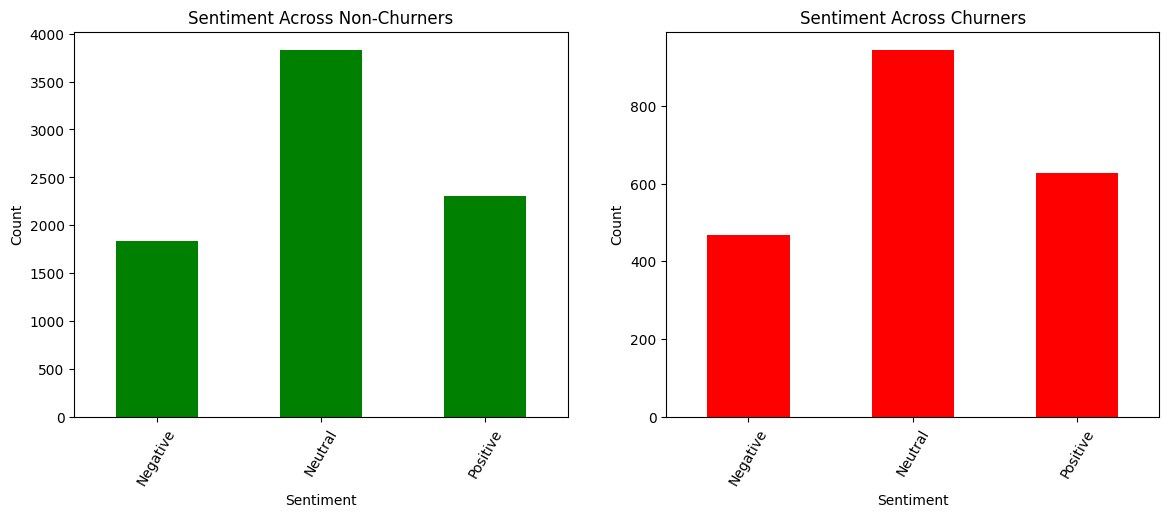

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot for Non-Churners (Exited = 0)
non_churn_dist = sentiment_churn_table.iloc[0]
non_churn_dist.plot(kind='bar', ax=axes[0], color='green')
axes[0].set_title("Sentiment Across Non-Churners")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis='x', rotation=60)

# Plot for Churners (Exited = 1)
churn_dist = sentiment_churn_table.iloc[1]
churn_dist.plot(kind='bar', ax=axes[1], color='red')
axes[1].set_title("Sentiment Across Churners")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis='x', rotation=60)

plt.show()

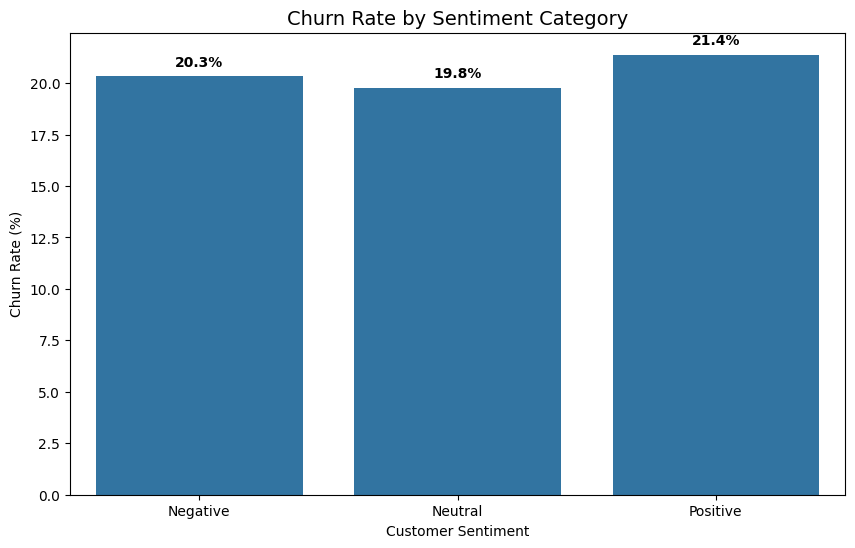

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Get percentage of chuners for each sentiment
sentiment_order = ['Negative', 'Neutral', 'Positive']
churn_rates = churn_merged.groupby('Sentiment')['Exited'].mean().reindex(sentiment_order) * 100

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=churn_rates.index, y=churn_rates.values)
ax.set_title('Churn Rate by Sentiment Category', fontsize=14)
ax.set_ylabel('Churn Rate (%)')
ax.set_xlabel('Customer Sentiment')

# Annotate bars with percentages
for i, v in enumerate(churn_rates.values):
    ax.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.show()

These graphs show us that review sentiment does not correlate with churn. Across churners and non-churners, the distribution of sentiment is roughly equal. And across all sentiment groups, the churn rate is between 19.8% and 21.4%, with positive reviewers having 1.1% higher churn. Therefore, review sentiment is not a strong predictor of churn. This is counter-intuitive from the expecation that churners would have high negative sentiment and non-churners would have high positive sentiment.

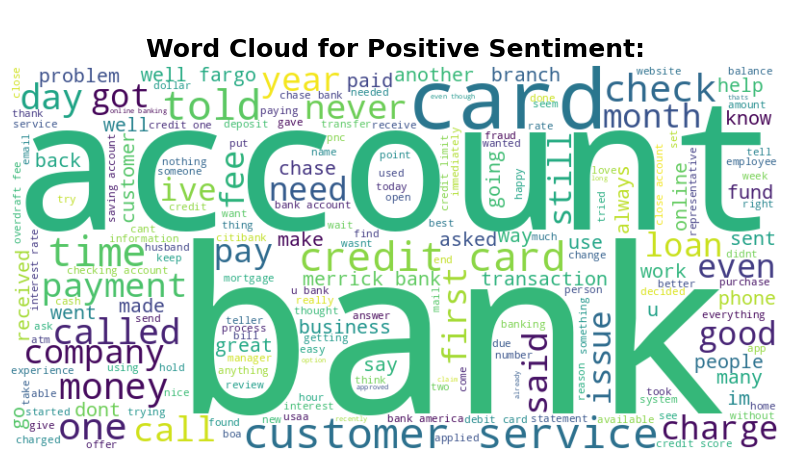

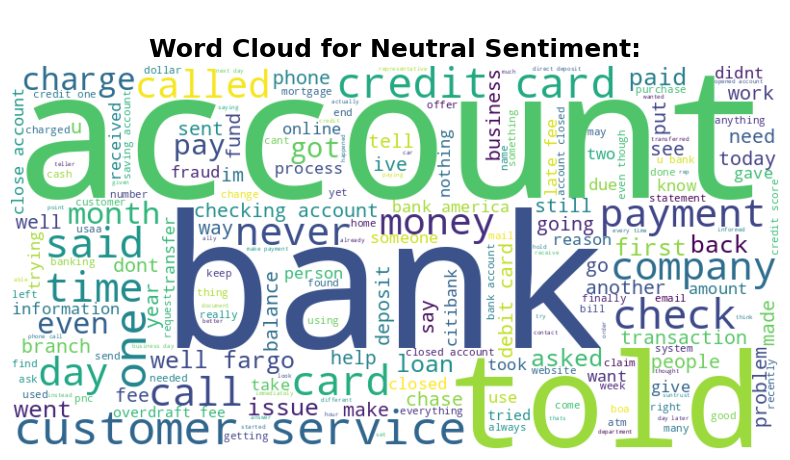

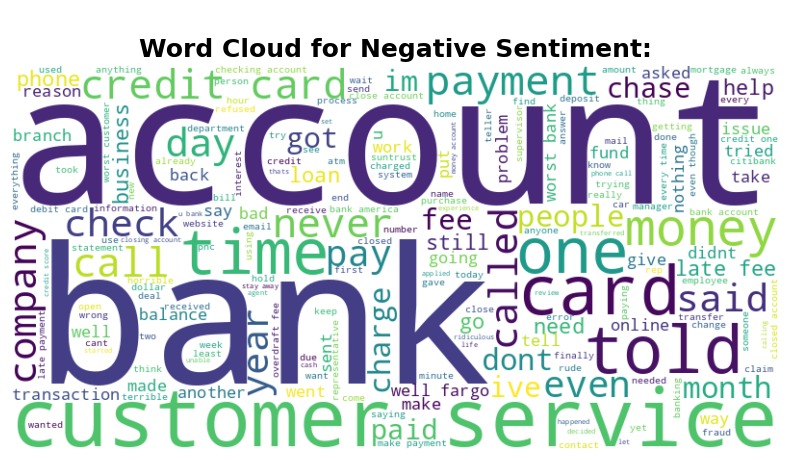

In [ ]:
from wordcloud import WordCloud

# Word clouds for each sentiment
def plot_wordcloud(sentiment_label, title):
    # Create one long string combining all reviews for this sentiment
    text = ' '.join(feedback[feedback['Sentiment'] == sentiment_label]['Processed_Text'])

    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(title, fontsize=18, fontweight="bold")
    plt.axis('off')
    plt.show()

for sentiment in ['Positive', 'Neutral', 'Negative']:
    plot_wordcloud(sentiment, f'\nWord Cloud for {sentiment} Sentiment:')

The words banks show that most reviews consist of the same common words such as "bank", "account", "customer service", etc. However, positive reviews include words like "good", "great", "better", and negative reviews include words like "bad", "worst bank", and "never". A better visual might be to remove words common across all sentiments such as "account" and "bank" to see words unique to each sentiment.

## Final Conclusions

Summarize:

- Key patterns found during exploration
  - The ratings (from 1-5) do not frequently match review sentiment (assuming sentiment analysis was accurate). Over 88% of the reviews were rated 1 or 2, but only 24.08% of the reviews had a negative sentiment.
  - Sentiment did not correlate with churning. Each sentiment group had approximately the same distribution of churners and non-churners.
- The text-cleaning and preprocessing approach
  - Tools such as Python's built-in string functions, regular expressions, NLTK tokenizer, and lemmatizer made it easy to boil the text down to the most important words in their root form. I chose to use the unprocessed text because reviews may contain important contextual words that are later removed including negators such as "not".
- The sentiment-labeling strategy
  - The sentiment analysis function provided by TextBlob made it easy to classify each review into positive, neutral, and negative. A threshold of 0.1 polarity was used to classify reviews as neutral since this is a common threshold and prevents reviews from being labeled as positive or negative if they are mostly neutral. Different thresholds could be experimented with. A good approach would be to select many reviews that have polarity near 0 and manually classifying them and checking their polarity scores to help determine which threshold is best.
  - The algorithm used by TextBlob is simple and may still struggle with complex human language patterns such as sarcasm, idioms, or slang. There could still be many misclassified reviews due to this. More advanced models such as recurrent neural networks or transformers could have more accuracy.
- The vectorization method used
  - The TF-IDF module offers an easy and powerful way to vectorize documents. It gives higher scores to words that are unique to a document. This allowed the machine learning models to learn which words lead to a positive or negative sentiment. Other techniques such as Bag-of-words or neural-network embeddings would have likely worked just as well or better. I carefully selected parameters such as `max_features=1000` to focus on important words and ignore noise, `ngram_range=(1,2)` to capture potentially significant pairs of words, and `min_df=1` to make sure no words were dropped.
- The strongest model and supporting evaluation results
  - The Logistic  Regression model beat the SVC model in all F1-scores, reaching an accuracy of almost 70%.
- Differences in performance across sentiment classes
  - The F1-scores for Negative and Positive were higher in the Logistic Regression model than the SVC model by 0.04, mainly driven by higher recall. The Neutral class had higher precision but lower recall, and an equal F1-score.
- The observed relationship between sentiment and churn
  - No relationship was found between review sentiment and churn. As seen in the plots, the distribution of sentiments was approximately equal for churners and non-churners. This could mean that the actual predicting factors for churning are either not reflected within the data, is completely random, or it could mean that the dataset was captured incorrectly or corrupted.
- Limitations of the analysis
  - The chosen sentiment analysis (TextBlob) may be too simple and limited to capture all sentiment perfectly. It also ignores word order which may affect meaning.
  - The models may not be the best ones. Other models such as XGBoost may perform better.
  - The dataset may not contain the right set of features to develop any predictive ability.
- Practical next steps or possible improvements
  - A good first step may be to investigate the dataset to make sure it was collected correctly. For example, checking why there are so many 1-star ratings despite so many neutral and positive reviews and only around 20% of actual churners.
  - More powerful tools may be chosen such as better sentiment analysis tools (BERT, sentence embeddings), and better models for this task (boosted trees such as XGBoost or LightGBM, or recurrent neural networks).